#Nama : Ye Heson Yikwa
#NIM : 251061047
#Prody : Sains data

# TUGAS 1
## Estimasi Titik dan Interval dengan Distribusi Z, Jackknife, dan Bootstrapping

**Topik:** Analisis data curah hujan harian sebanyak 100 sampel.

**Catatan penting:** Angka curah hujan di notebook ini adalah **data simulasi/contoh**, bukan hasil pengukuran dari stasiun cuaca. Jika dosen meminta data asli, ganti daftar data pada bagian **Input Data** dengan 100 data hasil pengamatan atau sumber data yang dapat dipertanggungjawabkan.

### Tujuan
1. Menghitung estimasi titik (rata-rata sampel).
2. Menghitung interval kepercayaan 95% menggunakan nilai kritis distribusi Z (tingkat kesalahan 5%).
3. Melakukan resampling Jackknife.
4. Melakukan resampling Bootstrapping sebanyak 1.000 iterasi.
5. Membandingkan rata-rata hasil resampling dan membuat kesimpulan.


## 1. Import Library

Library `numpy` digunakan untuk perhitungan angka, sedangkan `matplotlib` digunakan untuk membuat grafik.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Supaya hasil acak selalu sama setiap notebook dijalankan
np.random.seed(42)


## 2. Input Data (100 Sampel)

Satuan data adalah milimeter (mm). Data di bawah merupakan data simulasi untuk contoh pengerjaan.


In [2]:
data = np.array([7.8, 2.3, 23.1, 11.8, 12.2, 24.3, 14.2, 16.8, 10.9, 13.6, 10.3, 12.5, 23.1, 8.4, 5.1, 5.5, 10.0, 26.0, 7.2, 9.9, 21.2, 17.3, 7.6, 22.4, 53.8, 64.0, 8.0, 25.9, 28.7, 14.7, 18.3, 9.6, 6.4, 4.1, 34.0, 17.9, 16.9, 8.5, 9.4, 20.5, 8.9, 13.1, 8.4, 9.0, 20.6, 5.1, 12.9, 23.6, 2.1, 4.8, 50.0, 17.8, 6.2, 14.6, 11.4, 17.2, 21.3, 31.3, 1.3, 9.2, 41.5, 24.9, 20.6, 10.5, 29.4, 35.9, 40.6, 6.1, 5.8, 4.0, 51.8, 44.3, 1.0, 4.2, 17.4, 39.1, 21.8, 17.1, 12.5, 7.4, 4.1, 1.4, 24.6, 74.9, 6.8, 7.0, 24.6, 36.0, 22.1, 34.2, 10.7, 47.3, 23.0, 8.3, 30.6, 12.8, 20.1, 11.3, 21.9, 11.2], dtype=float)

print('Jumlah sampel:', len(data))
print('Data curah hujan (mm):')
print(data)

Jumlah sampel: 100
Data curah hujan (mm):
[ 7.8  2.3 23.1 11.8 12.2 24.3 14.2 16.8 10.9 13.6 10.3 12.5 23.1  8.4
  5.1  5.5 10.  26.   7.2  9.9 21.2 17.3  7.6 22.4 53.8 64.   8.  25.9
 28.7 14.7 18.3  9.6  6.4  4.1 34.  17.9 16.9  8.5  9.4 20.5  8.9 13.1
  8.4  9.  20.6  5.1 12.9 23.6  2.1  4.8 50.  17.8  6.2 14.6 11.4 17.2
 21.3 31.3  1.3  9.2 41.5 24.9 20.6 10.5 29.4 35.9 40.6  6.1  5.8  4.
 51.8 44.3  1.   4.2 17.4 39.1 21.8 17.1 12.5  7.4  4.1  1.4 24.6 74.9
  6.8  7.  24.6 36.  22.1 34.2 10.7 47.3 23.   8.3 30.6 12.8 20.1 11.3
 21.9 11.2]


In [3]:
# Pemeriksaan data
if len(data) != 100:
    raise ValueError("Data harus berjumlah tepat 100 sampel.")
if np.any(data < 0):
    raise ValueError("Curah hujan tidak boleh bernilai negatif.")

print("Jumlah data valid:", len(data))
print("Nilai minimum:", data.min(), "mm")
print("Nilai maksimum:", data.max(), "mm")


Jumlah data valid: 100
Nilai minimum: 1.0 mm
Nilai maksimum: 74.9 mm


## 3. Estimasi Titik dan Interval dengan Distribusi Z

Estimasi titik untuk rata-rata adalah rata-rata dari 100 sampel.

Tingkat kesalahan 5% berarti tingkat kepercayaan 95%. Untuk interval dua sisi, nilai kritis Z adalah 1,96.

Karena simpangan baku populasi biasanya tidak diketahui, perhitungan ini menggunakan simpangan baku sampel sebagai perkiraan. Rumus yang digunakan:

- Rata-rata sampel = jumlah seluruh data dibagi banyak data.
- Standard error = simpangan baku sampel dibagi akar jumlah sampel.
- Batas interval = rata-rata ± (1,96 × standard error).


In [4]:
n = len(data)
alpha = 0.05
z_kritis = 1.96  # Z untuk tingkat kepercayaan 95%

rata_rata = np.mean(data)
simpangan_baku = np.std(data, ddof=1)
standard_error = simpangan_baku / np.sqrt(n)
margin_error = z_kritis * standard_error

batas_bawah = rata_rata - margin_error
batas_atas = rata_rata + margin_error

print("HASIL ESTIMASI")
print(f"Jumlah sampel             : {n}")
print(f"Rata-rata (estimasi titik): {rata_rata:.3f} mm")
print(f"Simpangan baku sampel     : {simpangan_baku:.3f} mm")
print(f"Standard error            : {standard_error:.3f} mm")
print(f"Nilai Z                   : {z_kritis}")
print(f"Margin of error           : {margin_error:.3f} mm")
print(f"Interval kepercayaan 95%  : ({batas_bawah:.3f}, {batas_atas:.3f}) mm")


HASIL ESTIMASI
Jumlah sampel             : 100
Rata-rata (estimasi titik): 18.218 mm
Simpangan baku sampel     : 14.127 mm
Standard error            : 1.413 mm
Nilai Z                   : 1.96
Margin of error           : 2.769 mm
Interval kepercayaan 95%  : (15.449, 20.987) mm


## 4. Resampling dengan Metode Jackknife

Jackknife dilakukan dengan mengeluarkan satu data secara bergantian. Karena ada 100 sampel, akan diperoleh 100 nilai rata-rata Jackknife.

Rata-rata hasil Jackknife dihitung dari seluruh rata-rata sampel yang terbentuk. Standard error Jackknife juga dihitung sebagai informasi tambahan.


In [5]:
jackknife_means = []

for i in range(n):
    # Mengambil semua data kecuali data pada posisi ke-i
    sampel_jackknife = np.delete(data, i)
    jackknife_means.append(np.mean(sampel_jackknife))

jackknife_means = np.array(jackknife_means)
rata_rata_jackknife = np.mean(jackknife_means)

# Estimasi Jackknife terkoreksi bias dan standard error Jackknife
estimasi_jackknife_koreksi = n * rata_rata - (n - 1) * rata_rata_jackknife
se_jackknife = np.sqrt((n - 1) / n * np.sum((jackknife_means - rata_rata_jackknife) ** 2))

print("HASIL JACKKNIFE")
print("Jumlah resampling:", len(jackknife_means))
print(f"Rata-rata hasil Jackknife : {rata_rata_jackknife:.3f} mm")
print(f"Estimasi Jackknife koreksi: {estimasi_jackknife_koreksi:.3f} mm")
print(f"Standard error Jackknife  : {se_jackknife:.3f} mm")


HASIL JACKKNIFE
Jumlah resampling: 100
Rata-rata hasil Jackknife : 18.218 mm
Estimasi Jackknife koreksi: 18.218 mm
Standard error Jackknife  : 1.413 mm


## 5. Resampling dengan Metode Bootstrapping (1.000 Iterasi)

Bootstrapping dilakukan dengan mengambil sampel secara acak dari data yang tersedia. Pengambilan dilakukan dengan pengembalian, sehingga satu data dapat terpilih lebih dari sekali.

Setiap iterasi mengambil 100 data. Proses diulang sebanyak 1.000 kali, kemudian dihitung rata-rata dari 1.000 rata-rata sampel tersebut.


In [6]:
jumlah_iterasi = 1000
bootstrap_means = []

for i in range(jumlah_iterasi):
    sampel_bootstrap = np.random.choice(data, size=n, replace=True)
    bootstrap_means.append(np.mean(sampel_bootstrap))

bootstrap_means = np.array(bootstrap_means)
rata_rata_bootstrap = np.mean(bootstrap_means)

# Interval persentil 95% sebagai informasi tambahan
bootstrap_ci_bawah = np.percentile(bootstrap_means, 2.5)
bootstrap_ci_atas = np.percentile(bootstrap_means, 97.5)

print("HASIL BOOTSTRAPPING")
print("Jumlah iterasi:", len(bootstrap_means))
print(f"Rata-rata hasil Bootstrapping: {rata_rata_bootstrap:.3f} mm")
print(f"Interval persentil 95%       : ({bootstrap_ci_bawah:.3f}, {bootstrap_ci_atas:.3f}) mm")


HASIL BOOTSTRAPPING
Jumlah iterasi: 1000
Rata-rata hasil Bootstrapping: 18.275 mm
Interval persentil 95%       : (15.542, 21.189) mm


## 6. Perbandingan Hasil

Bagian ini menampilkan rata-rata data awal, rata-rata hasil Jackknife, dan rata-rata hasil Bootstrapping.


PERBANDINGAN HASIL
Rata-rata data awal       : 18.218 mm
Rata-rata Jackknife      : 18.218 mm
Rata-rata Bootstrapping  : 18.275 mm


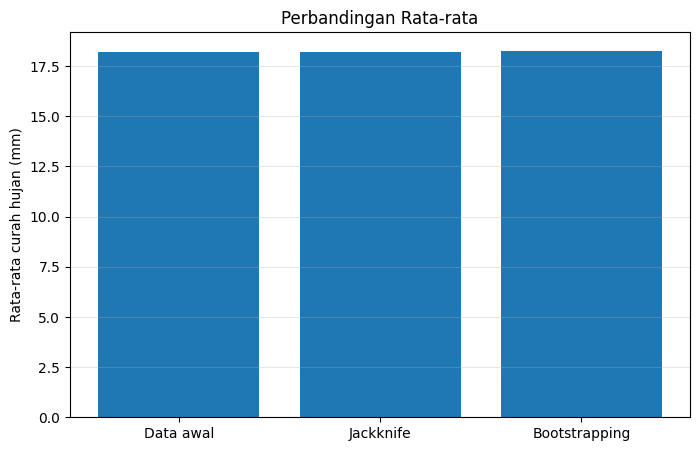

In [7]:
print("PERBANDINGAN HASIL")
print(f"Rata-rata data awal       : {rata_rata:.3f} mm")
print(f"Rata-rata Jackknife      : {rata_rata_jackknife:.3f} mm")
print(f"Rata-rata Bootstrapping  : {rata_rata_bootstrap:.3f} mm")

labels = ["Data awal", "Jackknife", "Bootstrapping"]
values = [rata_rata, rata_rata_jackknife, rata_rata_bootstrap]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)
plt.ylabel("Rata-rata curah hujan (mm)")
plt.title("Perbandingan Rata-rata")
plt.grid(axis="y", alpha=0.3)
plt.show()


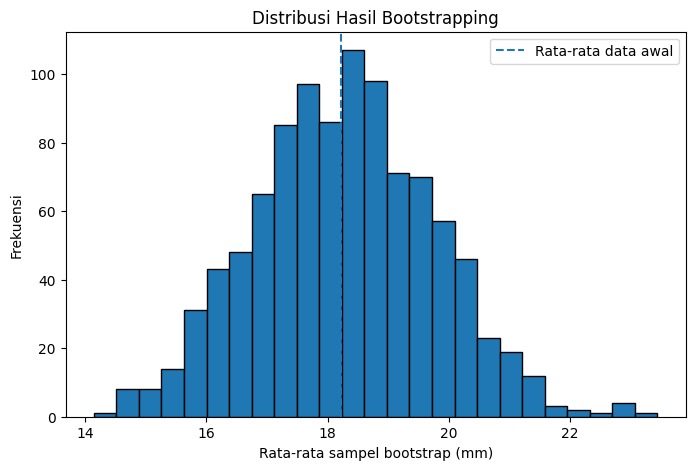

In [8]:
# Grafik sebaran rata-rata hasil Bootstrapping
plt.figure(figsize=(8, 5))
plt.hist(bootstrap_means, bins=25, edgecolor="black")
plt.axvline(rata_rata, linestyle="--", label="Rata-rata data awal")
plt.xlabel("Rata-rata sampel bootstrap (mm)")
plt.ylabel("Frekuensi")
plt.title("Distribusi Hasil Bootstrapping")
plt.legend()
plt.show()


## 7. Kesimpulan Otomatis

Jalankan sel berikut untuk menampilkan kesimpulan berdasarkan hasil perhitungan notebook.


In [9]:
print("KESIMPULAN")
print(f"1. Dari {n} sampel, estimasi titik rata-rata curah hujan adalah {rata_rata:.3f} mm.")
print(f"2. Dengan tingkat kepercayaan 95%, interval estimasi Z adalah {batas_bawah:.3f} sampai {batas_atas:.3f} mm.")
print(f"3. Metode Jackknife menghasilkan rata-rata {rata_rata_jackknife:.3f} mm dari {n} resampling.")
print(f"4. Metode Bootstrapping menghasilkan rata-rata {rata_rata_bootstrap:.3f} mm dari {jumlah_iterasi} iterasi.")
print("5. Hasil kedua metode resampling dapat dibandingkan dengan rata-rata data awal untuk melihat kedekatan hasil estimasinya.")


KESIMPULAN
1. Dari 100 sampel, estimasi titik rata-rata curah hujan adalah 18.218 mm.
2. Dengan tingkat kepercayaan 95%, interval estimasi Z adalah 15.449 sampai 20.987 mm.
3. Metode Jackknife menghasilkan rata-rata 18.218 mm dari 100 resampling.
4. Metode Bootstrapping menghasilkan rata-rata 18.275 mm dari 1000 iterasi.
5. Hasil kedua metode resampling dapat dibandingkan dengan rata-rata data awal untuk melihat kedekatan hasil estimasinya.


## 8. Catatan Pengumpulan

1. Pastikan data yang digunakan sesuai arahan dosen. Data di notebook ini masih berupa simulasi.
2. Jalankan semua sel dari atas ke bawah dengan memilih #Run all**.
3. Periksa apakah semua hasil angka dan grafik muncul tanpa error.
4. Simpan notebook dalam format `.ipynb`.
5. Unggah file `.ipynb` ke repository GitHub.

**Nama file yang disarankan:** `Tugas_1_Analisis_Eksplorasi_Data.ipynb`
